<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/2_4_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
!apt-get install libopencv-dev -y

!g++ -o odev4 odev4.cpp `pkg-config --cflags --libs opencv4` -pthread

!./odev4

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
4 Thread ile paralel histogram hesaplamasi baslatiliyor...
[BASARILI] 4 ayri bolgenin histogrami birlestirildi.
Ana histogram grafigi 'global_histogram.jpg' olarak kaydedildi.


In [17]:
%%writefile odev4.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <thread>
#include <vector>

using namespace cv;
using namespace std;

// Her bir alt bölge (ROI) için yerel histogram hesaplayan fonksiyon
void calculateHistogram(Mat roi, vector<int>& local_hist) {
    // Histogram dizisini sıfırla (8-bit için 256 seviye)
    local_hist.assign(256, 0);

    for (int r = 0; r < roi.rows; ++r) {
        for (int c = 0; c < roi.cols; ++c) {
            // Pikselin parlaklık değerini okuyup ilgili indeksteki sayacı 1 artırıyoruz
            int pixel_val = roi.at<uchar>(r, c);
            local_hist[pixel_val]++;
        }
    }
}

int main() {
    // 1. Görüntüyü siyah-beyaz (tek kanallı) oku
    Mat img = imread("test_image.jpg", IMREAD_GRAYSCALE);
    if (img.empty()) {
        cout << "Gorsel bulunamadi! Lutfen 'test_image.jpg' dosyasini sol tarafa yukleyin." << endl;
        return -1;
    }

    int w = img.cols;
    int h = img.rows;
    int half_w = w / 2;
    int half_h = h / 2;

    // 2. Görüntüyü 4 parçaya (ROI) böl
    Mat q1 = img(Rect(0, 0, half_w, half_h));                   // Sol Üst
    Mat q2 = img(Rect(half_w, 0, w - half_w, half_h));          // Sağ Üst
    Mat q3 = img(Rect(0, half_h, half_w, h - half_h));          // Sol Alt
    Mat q4 = img(Rect(half_w, half_h, w - half_w, h - half_h)); // Sağ Alt

    // 3. Thread'ler için birbirinden bağımsız 4 ayrı yerel histogram dizisi oluştur
    vector<int> hist1(256, 0), hist2(256, 0), hist3(256, 0), hist4(256, 0);

    cout << "4 Thread ile paralel histogram hesaplamasi baslatiliyor..." << endl;

    // 4. Thread'leri başlat.
    thread t1(calculateHistogram, q1, std::ref(hist1));
    thread t2(calculateHistogram, q2, std::ref(hist2));
    thread t3(calculateHistogram, q3, std::ref(hist3));
    thread t4(calculateHistogram, q4, std::ref(hist4));


    t1.join();
    t2.join();
    t3.join();
    t4.join();


    vector<int> global_hist(256, 0);
    int max_val = 0; // Grafiği çizerken yüksekliği ölçeklemek için en büyük frekansı bulacağız

    for (int i = 0; i < 256; ++i) {
        global_hist[i] = hist1[i] + hist2[i] + hist3[i] + hist4[i];
        if (global_hist[i] > max_val) {
            max_val = global_hist[i];
        }
    }

    cout << "[BASARILI] 4 ayri bolgenin histogrami birlestirildi." << endl;

    // 6. Ana histogramı görselleştirmek için boş bir tuval oluştur (512x400 piksel boyutunda)
    int hist_w = 512, hist_h = 400;
    int bin_w = cvRound((double)hist_w / 256);
    Mat histImage(hist_h, hist_w, CV_8UC1, Scalar(255)); // Beyaz arka plan

    // Histogram grafiğini çizgi olarak tuvale çiz
    for (int i = 1; i < 256; ++i) {
        // Frekans değerlerini tuval boyuna (400 piksel) sığacak şekilde normalize et
        int val1 = cvRound(((double)global_hist[i-1] / max_val) * hist_h);
        int val2 = cvRound(((double)global_hist[i] / max_val) * hist_h);

        line(histImage,
             Point(bin_w * (i - 1), hist_h - val1),
             Point(bin_w * (i), hist_h - val2),
             Scalar(0), 2, 8, 0); // Siyah çizgi ile birleştir
    }

    // Çizilen histogramı kaydet
    imwrite("global_histogram.jpg", histImage);
    cout << "Ana histogram grafigi 'global_histogram.jpg' olarak kaydedildi." << endl;

    return 0;
}

Overwriting odev4.cpp


--- 1. Orijinal Görüntü ---


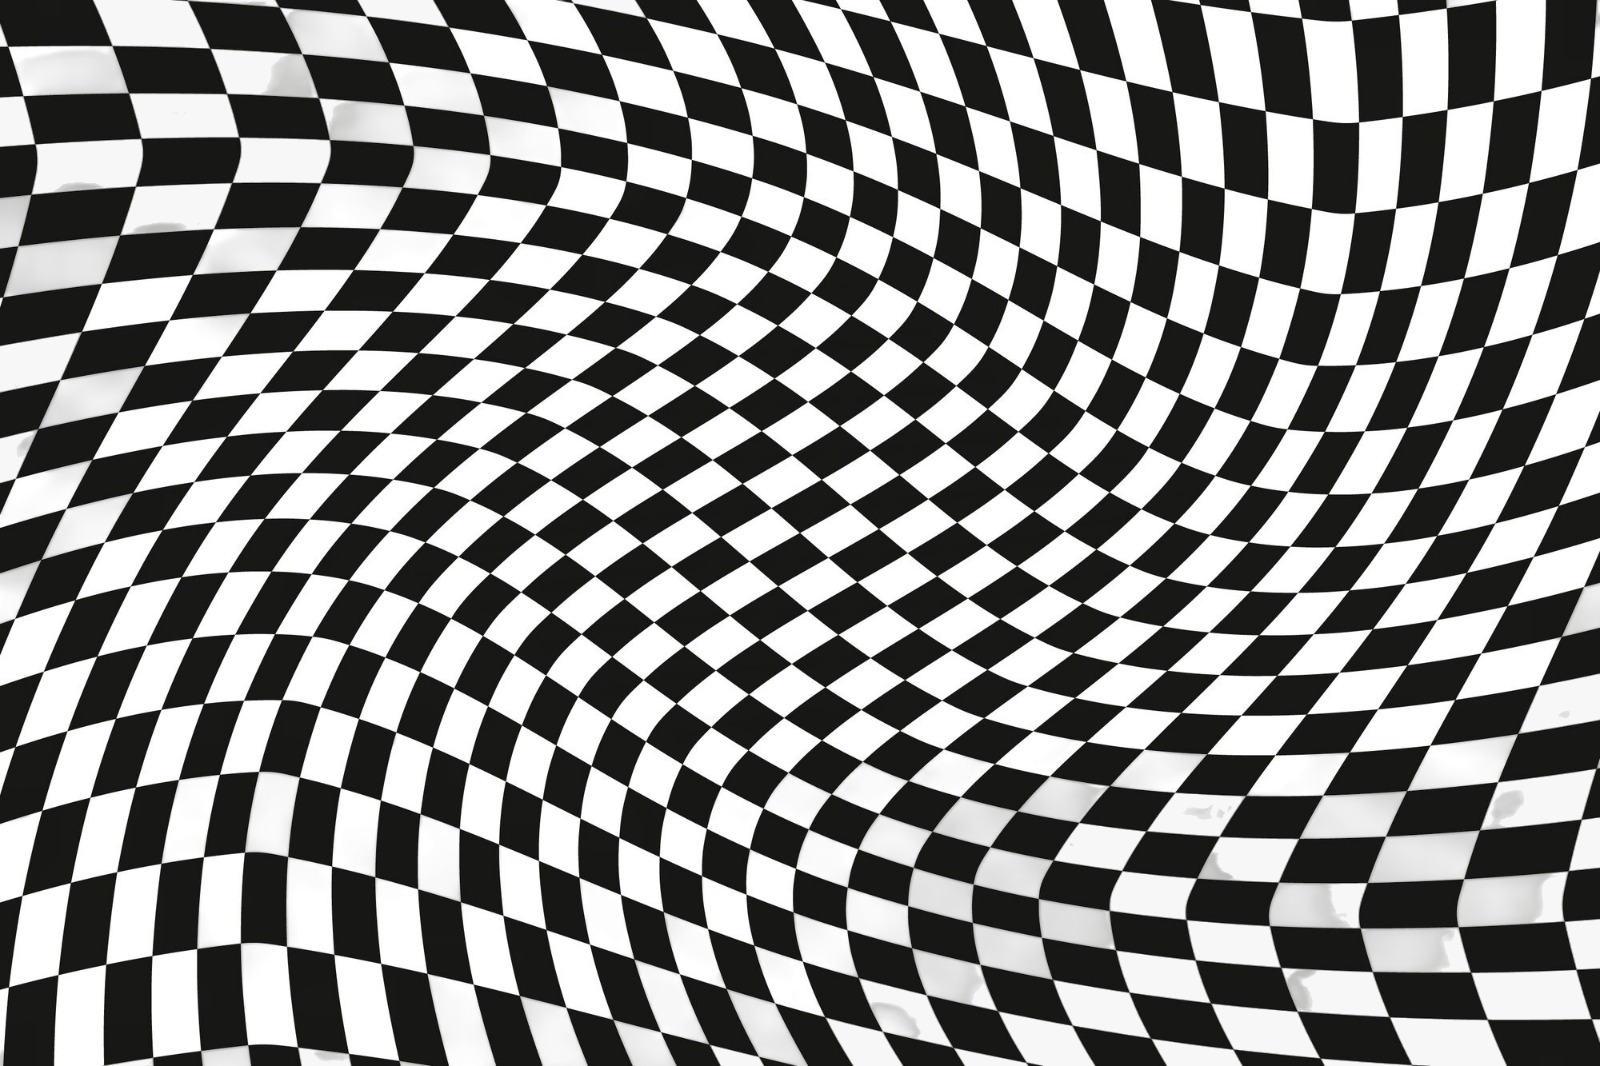


--- 2. OLUŞTURULAN HİSTOGRAM GRAFİĞİ ---


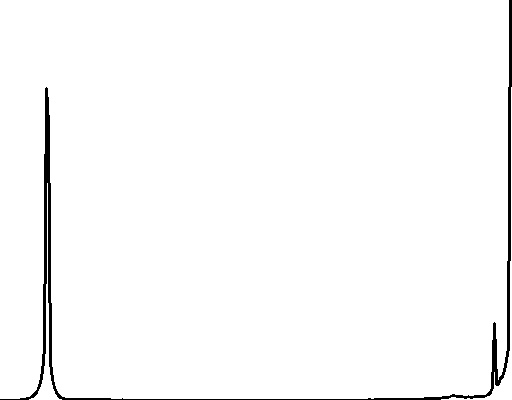

In [18]:
from IPython.display import Image, display

print("--- 1. Orijinal Görüntü ---")
display(Image(filename='test_image.jpg'))

print("\n--- 2. OLUŞTURULAN HİSTOGRAM GRAFİĞİ ---")
display(Image(filename='global_histogram.jpg'))